M1


performs the mass iteration, calculates power and mission radius, and checks the structural constraints.

In [ ]:

import math

# GIVEN CONSTANTS
rho = 1.225
g = 9.81
n = 4
eta = 0.85
Pav = 30
CdA = 0.08
FM = 0.65
Vtip = 110
Ecf = 70e9
rhocf = 1550

# TRIAL DESIGN
D = 0.575
E = 1100
d = 27.5e-3
t = 1.5e-3
V = 15

# GEOMETRY
L = 0.78 * D - 0.08

Atube = (math.pi / 4) * (
    d**2 - (d - 2*t)**2
)

I = (math.pi / 64) * (
    d**4 - (d - 2*t)**4
)

marm = rhocf * Atube * L

# FIXED-POINT MASS ITERATION
def calculate_mass(payload):

    B = (
        payload + 0.60 + 0.25 + E/150
        + n * rhocf * Atube * L
        + n * (0.12 + 0.05*(D/0.6)**2.5)
    )

    m = B
    history = [m]

    for k in range(1000):

        Tmax = 2*m*g/n

        m_new = (
            payload + 0.60 + 0.25 + E/150
            + n*rhocf*Atube*L
            + n*(0.12 + 0.004*Tmax
                 + 0.05*(D/0.6)**2.5)
        )

        history.append(m_new)

        if abs(m_new - m) < 1e-12:
            m = m_new
            break

        m = m_new

    return m, history


# LOADED AND EMPTY MASS
m_loaded, hist_loaded = calculate_mass(2.5)
m_empty, hist_empty = calculate_mass(0.0)


# POWER CALCULATIONS
def calculate_power(m):

    W = m*g
    A = math.pi*D**2/4

    vh = math.sqrt(W/(2*rho*n*A))

    vi = math.sqrt(
        -V**2/2
        + math.sqrt(V**4/4 + vh**4)
    )

    mu = V/Vtip

    P_hover = W*vh/(FM*eta) + Pav

    P_cruise = (
        W*vi
        + W*vh*(math.sqrt(1 + 4.65*mu**2) - 1)
        + 0.5*rho*CdA*V**3
    )/(FM*eta) + Pav

    return vh, vi, P_hover, P_cruise


loaded = calculate_power(m_loaded)
empty = calculate_power(m_empty)

# MISSION RADIUS
Euse = 3600*0.80*0.85*E

R = V * (
    Euse - 60*(loaded[2] + empty[2])
) / (
    loaded[3] + empty[3]
)

# STRUCTURAL CHECKS
Tmax = 2*m_loaded*g/n

sigma = Tmax*L*(d/2)/I

delta = Tmax*L**3/(3*Ecf*I)

mtip = (
    0.12 + 0.004*Tmax
    + 0.05*(D/0.6)**2.5
)

f1 = (1/(2*math.pi))*math.sqrt(
    3*Ecf*I /
    (L**3*(mtip + 0.24*marm))
)

frequency_required = 1.15*Vtip/(math.pi*D)

slenderness = d/t

# PRINT RESULTS
print("LOADED MASS:", m_loaded, "kg")
print("EMPTY MASS:", m_empty, "kg")
print("MAXIMUM THRUST:", Tmax, "N")

print("\nLOADED HOVER POWER:", loaded[2], "W")
print("EMPTY HOVER POWER:", empty[2], "W")

print("\nLOADED CRUISE POWER:", loaded[3], "W")
print("EMPTY CRUISE POWER:", empty[3], "W")

print("\nMISSION RADIUS:", R/1000, "km")

print("\nSTRUCTURAL CHECKS")
print("Bending stress:", sigma/1e6, "MPa")
print("Tip deflection:", delta*1000, "mm")
print("Allowable deflection:", 0.01*L*1000, "mm")
print("Natural frequency:", f1, "Hz")
print("Required frequency:", frequency_required, "Hz")
print("Slenderness:", slenderness)

print("\nMASS ITERATIONS:", len(hist_loaded)-1)
print("FINAL MASS CHANGE:",
      abs(hist_loaded[-1]-hist_loaded[-2]), "kg")


LOADED MASS: 12.612935985532015 kg
EMPTY MASS: 9.900026878838737 kg
MAXIMUM THRUST: 61.86645100903454 N

LOADED HOVER POWER: 1591.5996135070775 W
EMPTY HOVER POWER: 1115.925336483602 W

LOADED CRUISE POWER: 1105.6656545713874 W
EMPTY CRUISE POWER: 816.4011588481261 W

MISSION RADIUS: 19.74709062141443 km

STRUCTURAL CHECKS
Bending stress: 30.177349901807975 MPa
Tip deflection: 1.419168915048929 mm
Allowable deflection: 3.6849999999999996 mm
Natural frequency: 50.72165422452388 Hz
Required frequency: 70.02817496043396 Hz
Slenderness: 18.333333333333332

MASS ITERATIONS: 12
FINAL MASS CHANGE: 6.341593916658894e-13 kg


MDA convergence plot

LOADED
Exact mass: 12.612935985532069 kg
Iterations: 13

EMPTY
Exact mass: 9.90002687883878 kg
Iterations: 13


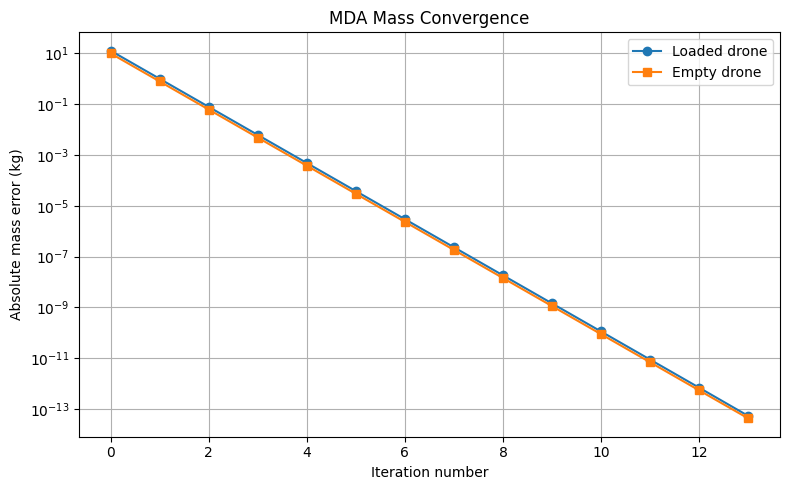

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Trial design (same values as the previous calculation)
D = 0.575       # rotor diameter (m)
E = 1100.0      # battery capacity (Wh)
d = 0.0275      # arm outer diameter (m)
t = 0.0015      # arm wall thickness (m)

# Given constants
rho_cf = 1550.0
n = 4
g = 9.81
rho_air = 1.225
m_fixed = 0.60
m_plate = 0.25
e_b = 150.0

# Arm geometry
L = 0.78 * D - 0.08
A_tube = (np.pi / 4) * (d**2 - (d - 2*t)**2)

# Mass term independent of the unknown total mass
B_base = (
    2.5 + m_fixed + m_plate + E/e_b
    + n*rho_cf*A_tube*L
    + n*(0.12 + 0.05*(D/0.6)**2.5)
)

# Exact coefficient from the thrust-dependent motor mass
coefficient = 0.008 * g
exact_mass_factor = 1 - coefficient

def mass_iteration(payload, initial_mass=0.0, tolerance=1e-12):
    B = B_base - 2.5 + payload
    exact_mass = B / exact_mass_factor

    mass = initial_mass
    estimates = [mass]

    for iteration in range(1, 101):
        maximum_thrust = 2 * mass * g / n

        new_mass = (
            payload + m_fixed + m_plate + E/e_b
            + n*rho_cf*A_tube*L
            + n*(0.12 + 0.004*maximum_thrust
                 + 0.05*(D/0.6)**2.5)
        )

        estimates.append(new_mass)

        if abs(new_mass - mass) < tolerance:
            break

        mass = new_mass

    errors = [abs(value - exact_mass) for value in estimates]

    return exact_mass, estimates, errors, iteration

# Loaded and empty cases
loaded_exact, loaded_estimates, loaded_errors, loaded_iterations = (
    mass_iteration(payload=2.5)
)

empty_exact, empty_estimates, empty_errors, empty_iterations = (
    mass_iteration(payload=0.0)
)

print("LOADED")
print("Exact mass:", loaded_exact, "kg")
print("Iterations:", loaded_iterations)

print("\nEMPTY")
print("Exact mass:", empty_exact, "kg")
print("Iterations:", empty_iterations)

# Plot convergence error
plt.figure(figsize=(8, 5))

plt.semilogy(
    range(len(loaded_errors)),
    loaded_errors,
    marker="o",
    label="Loaded drone"
)

plt.semilogy(
    range(len(empty_errors)),
    empty_errors,
    marker="s",
    label="Empty drone"
)

plt.xlabel("Iteration number")
plt.ylabel("Absolute mass error (kg)")
plt.title("MDA Mass Convergence")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


Replacing d

LOADED
Exact mass: 12.665510837912572 kg
Iterations: 13

EMPTY
Exact mass: 9.952601731219284 kg
Iterations: 13


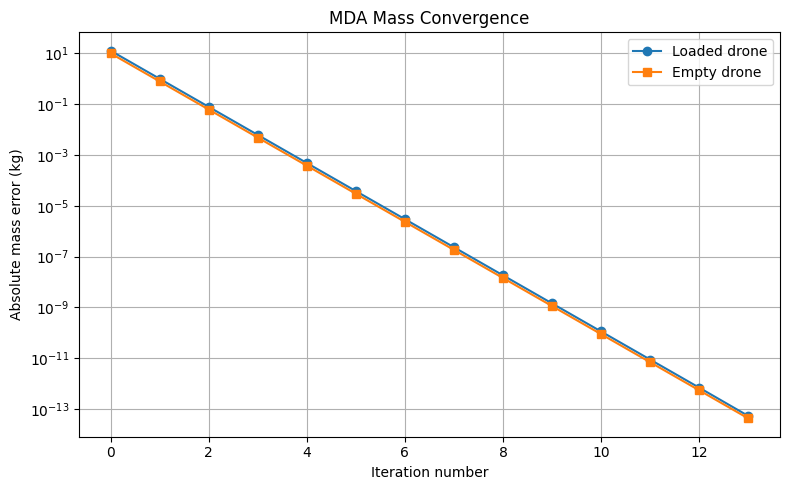

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Trial design (same values as the previous calculation)
D = 0.575       # rotor diameter (m)
E = 1100.0      # battery capacity (Wh)
d = 0.032      # arm outer diameter (m)
t = 0.0015      # arm wall thickness (m)

# Given constants
rho_cf = 1550.0
n = 4
g = 9.81
rho_air = 1.225
m_fixed = 0.60
m_plate = 0.25
e_b = 150.0

# Arm geometry
L = 0.78 * D - 0.08
A_tube = (np.pi / 4) * (d**2 - (d - 2*t)**2)

# Mass term independent of the unknown total mass
B_base = (
    2.5 + m_fixed + m_plate + E/e_b
    + n*rho_cf*A_tube*L
    + n*(0.12 + 0.05*(D/0.6)**2.5)
)

# Exact coefficient from the thrust-dependent motor mass
coefficient = 0.008 * g
exact_mass_factor = 1 - coefficient

def mass_iteration(payload, initial_mass=0.0, tolerance=1e-12):
    B = B_base - 2.5 + payload
    exact_mass = B / exact_mass_factor

    mass = initial_mass
    estimates = [mass]

    for iteration in range(1, 101):
        maximum_thrust = 2 * mass * g / n

        new_mass = (
            payload + m_fixed + m_plate + E/e_b
            + n*rho_cf*A_tube*L
            + n*(0.12 + 0.004*maximum_thrust
                 + 0.05*(D/0.6)**2.5)
        )

        estimates.append(new_mass)

        if abs(new_mass - mass) < tolerance:
            break

        mass = new_mass

    errors = [abs(value - exact_mass) for value in estimates]

    return exact_mass, estimates, errors, iteration

# Loaded and empty cases
loaded_exact, loaded_estimates, loaded_errors, loaded_iterations = (
    mass_iteration(payload=2.5)
)

empty_exact, empty_estimates, empty_errors, empty_iterations = (
    mass_iteration(payload=0.0)
)

print("LOADED")
print("Exact mass:", loaded_exact, "kg")
print("Iterations:", loaded_iterations)

print("\nEMPTY")
print("Exact mass:", empty_exact, "kg")
print("Iterations:", empty_iterations)

# Plot convergence error
plt.figure(figsize=(8, 5))

plt.semilogy(
    range(len(loaded_errors)),
    loaded_errors,
    marker="o",
    label="Loaded drone"
)

plt.semilogy(
    range(len(empty_errors)),
    empty_errors,
    marker="s",
    label="Empty drone"
)

plt.xlabel("Iteration number")
plt.ylabel("Absolute mass error (kg)")
plt.title("MDA Mass Convergence")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

import math

# =====================================================
# M1: MULTIDISCIPLINARY DESIGN OPTIMIZATION
# TRIAL DESIGN - ARM DIAMETER INCREASED TO 32 mm
# =====================================================

# 1. DESIGN VARIABLES
D = 0.575          # Rotor diameter (m)
E = 1100.0         # Battery capacity (Wh)
d = 0.032          # Arm outer diameter (m) - CHANGED
t = 0.0025         # Arm wall thickness (m)
V = 15.0           # Cruise speed (m/s)

# 2. GIVEN CONSTANTS
rho = 1.225        # Air density (kg/m^3)
g = 9.81           # Gravity (m/s^2)
n = 4              # Number of rotors

m_fixed = 0.60     # Fixed mass (kg)
m_plate = 0.25     # Plate mass (kg)
m_payload = 2.5    # Maximum payload (kg)

e_b = 150.0        # Battery specific energy (Wh/kg)

rho_cf = 1550.0    # CFRP density (kg/m^3)
E_cf = 70e9        # CFRP Young's modulus (Pa)
sigma_allow = 300e6 / 1.5

FM = 0.65          # Figure of merit
eta = 0.85         # Motor/ESC efficiency

P_av = 30.0        # Avionics power (W)
CdA = 0.08         # Drag area (m^2)

V_tip = 110.0      # Rotor tip speed (m/s)

# 3. ARM GEOMETRY
L = 0.78 * D - 0.08

A_tube = (math.pi / 4) * (
    d**2 - (d - 2*t)**2
)

I = (math.pi / 64) * (
    d**4 - (d - 2*t)**4
)

m_arm = rho_cf * A_tube * L

# 4. MASS ITERATION (MDA)
def calculate_mass(payload):

    mass = 10.0
    tolerance = 1e-12

    for iteration in range(1, 101):

        T_max = 2 * mass * g / n

        new_mass = (
            payload
            + m_fixed
            + m_plate
            + E / e_b
            + n * m_arm
            + n * (
                0.12
                + 0.004 * T_max
                + 0.05 * (D / 0.6)**2.5
            )
        )

        mass_change = abs(new_mass - mass)

        mass = new_mass

        if mass_change < tolerance:
            break

    return mass, iteration, mass_change


# 5. LOADED AND EMPTY MASSES
m_loaded, iter_loaded, change_loaded = calculate_mass(
    m_payload
)

m_empty, iter_empty, change_empty = calculate_mass(
    0.0
)

# Maximum thrust per rotor using loaded mass
T_max = 2 * m_loaded * g / n

# Motor and propeller mass per rotor
m_tip = (
    0.12
    + 0.004 * T_max
    + 0.05 * (D / 0.6)**2.5
)

# 6. HOVER AND CRUISE POWER
def calculate_power(mass):

    W = mass * g

    rotor_area = math.pi * D**2 / 4

    # Induced velocity during hover
    v_h = math.sqrt(
        W / (2 * rho * n * rotor_area)
    )

    # Induced velocity during forward flight
    v_i = math.sqrt(
        -V**2 / 2
        + math.sqrt(V**4 / 4 + v_h**4)
    )

    # Hover power
    P_hover = (
        W * v_h / (FM * eta)
        + P_av
    )

    # Advance ratio
    mu = V / V_tip

    # Cruise power
    P_cruise = (
        (
            W * v_i
            + W * v_h * (
                math.sqrt(1 + 4.65 * mu**2) - 1
            )
            + 0.5 * rho * CdA * V**3
        ) / (FM * eta)
        + P_av
    )

    return P_hover, P_cruise, v_h, v_i


# Loaded power
P_hover_loaded, P_cruise_loaded, vh_loaded, vi_loaded = (
    calculate_power(m_loaded)
)

# Empty power
P_hover_empty, P_cruise_empty, vh_empty, vi_empty = (
    calculate_power(m_empty)
)

# 7. MISSION RADIUS
E_use = 3600 * 0.80 * 0.85 * E

R = V * (
    E_use
    - 60 * (P_hover_loaded + P_hover_empty)
) / (
    P_cruise_loaded + P_cruise_empty
)

# Convert metres to kilometres
R_km = R / 1000

# 8. STRUCTURAL CHECKS

# Bending stress
sigma = (
    T_max * L * (d / 2)
) / I

sigma_MPa = sigma / 1e6

# Tip deflection
delta = (
    T_max * L**3
) / (
    3 * E_cf * I
)

delta_mm = delta * 1000

allowable_deflection = 0.01 * L
allowable_deflection_mm = allowable_deflection * 1000

# First natural frequency
f1 = (1 / (2 * math.pi)) * math.sqrt(
    (3 * E_cf * I)
    / (
        L**3 * (
            m_tip + 0.24 * m_arm
        )
    )
)

# Required natural frequency
f_required = 1.15 * V_tip / (math.pi * D)

# Slenderness ratio
slenderness = d / t

# 9. DISPLAY RESULTS
print("\n========== M1 DESIGN RESULTS ==========")

print("\nDESIGN VARIABLES")
print("Rotor diameter:", D, "m")
print("Battery capacity:", E, "Wh")
print("Arm diameter:", d * 1000, "mm")
print("Wall thickness:", t * 1000, "mm")
print("Cruise speed:", V, "m/s")

print("\nMASS RESULTS")
print("Loaded mass:", m_loaded, "kg")
print("Empty mass:", m_empty, "kg")
print("Maximum thrust:", T_max, "N")

print("\nPOWER RESULTS")
print("Loaded hover power:", P_hover_loaded, "W")
print("Empty hover power:", P_hover_empty, "W")
print("Loaded cruise power:", P_cruise_loaded, "W")
print("Empty cruise power:", P_cruise_empty, "W")

print("\nMISSION PERFORMANCE")
print("Usable battery energy:", E_use, "J")
print("Mission radius:", R_km, "km")

print("\nSTRUCTURAL CHECKS")

print("Bending stress:", sigma_MPa, "MPa")
print("Allowable stress:", sigma_allow / 1e6, "MPa")

print("Tip deflection:", delta_mm, "mm")
print("Allowable deflection:", allowable_deflection_mm, "mm")

print("Natural frequency:", f1, "Hz")
print("Required frequency:", f_required, "Hz")

print("Slenderness:", slenderness)

print("\nSTRUCTURAL FEASIBILITY")

print(
    "Bending stress:",
    "PASS" if sigma <= sigma_allow else "FAIL"
)

print(
    "Tip deflection:",
    "PASS" if delta <= allowable_deflection else "FAIL"
)

print(
    "Natural frequency:",
    "PASS" if f1 >= f_required else "FAIL"
)

print(
    "Slenderness:",
    "PASS" if slenderness <= 40 else "FAIL"
)

print("\nMASS CONVERGENCE")
print("Loaded iterations:", iter_loaded)
print("Empty iterations:", iter_empty)
print("Loaded final mass change:", change_loaded, "kg")
print("Empty final mass change:", change_empty, "kg")

print("\n========== END OF CALCULATION ==========")



========== M1 DESIGN RESULTS ==========

DESIGN VARIABLES
Rotor diameter: 0.575 m
Battery capacity: 1100.0 Wh
Arm diameter: 32.0 mm
Wall thickness: 2.5 mm
Cruise speed: 15.0 m/s

MASS RESULTS
Loaded mass: 12.883599114453911 kg
Empty mass: 10.170690007760625 kg
Maximum thrust: 63.19405365639644 N

POWER RESULTS
Loaded hover power: 1642.134268848923 W
Empty hover power: 1160.761548719118 W
Loaded cruise power: 1137.9566288425815 W
Empty cruise power: 842.4073104026289 W

MISSION PERFORMANCE
Usable battery energy: 2692800.0 J
Mission radius: 19.122441594559724 km

STRUCTURAL CHECKS
Bending stress: 14.67776258536634 MPa
Allowable stress: 200.0 MPa
Tip deflection: 0.5931923828668786 mm
Allowable deflection: 3.6849999999999996 mm
Natural frequency: 77.48189961900708 Hz
Required frequency: 70.02817496043396 Hz
Slenderness: 12.8

STRUCTURAL FEASIBILITY
Bending stress: PASS
Tip deflection: PASS
Natural frequency: PASS
Slenderness: PASS

MASS CONVERGENCE
Loaded iterations: 13
Empty iterations: 

calculates the mass internally using the exact solution of the MDA mass equation, evaluates the power and radius, and passes the structural constraints to the optimizer.

In [1]:

import math
import numpy as np
from scipy.optimize import minimize

# ==========================================================
# M1: MDF OPTIMIZATION
# Objective: Maximize mission radius at 2.5 kg payload
# ==========================================================

# GIVEN CONSTANTS
rho = 1.225
g = 9.81
n = 4

m_fixed = 0.60
m_plate = 0.25
payload = 2.5

e_b = 150.0
rho_cf = 1550.0
E_cf = 70e9
sigma_allow = 200e6

FM = 0.65
eta = 0.85
P_av = 30.0
CdA = 0.08
V_tip = 110.0

# ----------------------------------------------------------
# DISCIPLINE ANALYSIS: MASS, POWER, RADIUS AND STRUCTURE
# ----------------------------------------------------------

def evaluate_design(x):

    D, E, d_mm, t_mm, V = x

    # Convert arm dimensions from mm to m
    d = d_mm / 1000.0
    t = t_mm / 1000.0

    L = 0.78 * D - 0.08

    # Prevent invalid geometry
    if d <= 2*t or L <= 0:
        raise ValueError("Invalid arm geometry.")

    # Tube cross-sectional area
    A_tube = (math.pi / 4) * (
        d**2 - (d - 2*t)**2
    )

    # Second moment of area
    I = (math.pi / 64) * (
        d**4 - (d - 2*t)**4
    )

    # Mass of one arm
    m_arm = rho_cf * A_tube * L

    # Exact solution of the MDA mass equation
    def calculate_mass(pay):

        B = (
            pay + m_fixed + m_plate + E/e_b
            + n*m_arm
            + n*(0.12 + 0.05*(D/0.6)**2.5)
        )

        return B / (1 - 0.008*g)

    m_loaded = calculate_mass(payload)
    m_empty = calculate_mass(0.0)

    # Maximum thrust per rotor
    T_max = 2*m_loaded*g/n

    # Motor and propeller mass per rotor
    m_tip = (
        0.12 + 0.004*T_max
        + 0.05*(D/0.6)**2.5
    )

    # ------------------------------------------------------
    # POWER CALCULATIONS
    # ------------------------------------------------------

    def calculate_power(mass):

        W = mass*g
        rotor_area = math.pi*D**2/4

        v_h = math.sqrt(
            W/(2*rho*n*rotor_area)
        )

        v_i = math.sqrt(
            -V**2/2
            + math.sqrt(V**4/4 + v_h**4)
        )

        P_hover = (
            W*v_h/(FM*eta) + P_av
        )

        mu = V/V_tip

        P_cruise = (
            (
                W*v_i
                + W*v_h*(
                    math.sqrt(1 + 4.65*mu**2) - 1
                )
                + 0.5*rho*CdA*V**3
            )/(FM*eta)
            + P_av
        )

        return P_hover, P_cruise

    P_hover_loaded, P_cruise_loaded = calculate_power(
        m_loaded
    )

    P_hover_empty, P_cruise_empty = calculate_power(
        m_empty
    )

    # ------------------------------------------------------
    # MISSION RADIUS
    # ------------------------------------------------------

    E_use = 3600*0.80*0.85*E

    R = (
        V*(E_use - 60*(
            P_hover_loaded + P_hover_empty
        ))
        /
        (P_cruise_loaded + P_cruise_empty)
    )

    # ------------------------------------------------------
    # STRUCTURAL CONSTRAINTS
    # ------------------------------------------------------

    # Bending stress
    stress = T_max*L*(d/2)/I

    # Tip deflection
    deflection = (
        T_max*L**3/(3*E_cf*I)
    )

    allowable_deflection = 0.01*L

    # First natural frequency
    f1 = (
        1/(2*math.pi)
        * math.sqrt(
            3*E_cf*I
            /
            (L**3*(m_tip + 0.24*m_arm))
        )
    )

    f_required = 1.15*V_tip/(math.pi*D)

    # Slenderness
    slenderness = d/t

    return {
        "radius": R,
        "loaded_mass": m_loaded,
        "empty_mass": m_empty,
        "thrust": T_max,
        "stress": stress,
        "deflection": deflection,
        "allowable_deflection": allowable_deflection,
        "frequency": f1,
        "required_frequency": f_required,
        "slenderness": slenderness
    }


# ----------------------------------------------------------
# OBJECTIVE FUNCTION
# Negative sign because minimize() is used
# ----------------------------------------------------------

def objective(x):

    results = evaluate_design(x)

    radius_km = results["radius"]/1000.0

    return -radius_km


# ----------------------------------------------------------
# STRUCTURAL CONSTRAINTS
# All constraints must be >= 0
# ----------------------------------------------------------

def structural_constraints(x):

    r = evaluate_design(x)

    return np.array([

        # Bending stress
        (200e6 - r["stress"])/200e6,

        # Tip deflection
        (
            r["allowable_deflection"]
            - r["deflection"]
        )/r["allowable_deflection"],

        # Natural frequency
        (
            r["frequency"]
            - r["required_frequency"]
        )/r["required_frequency"],

        # Slenderness
        (40 - r["slenderness"])/40

    ])


# ----------------------------------------------------------
# DESIGN VARIABLE BOUNDS
# D, E, d(mm), t(mm), V
# ----------------------------------------------------------

bounds = [
    (0.35, 0.80),
    (200, 2000),
    (15, 40),
    (0.5, 2.5),
    (8, 22)
]


# ----------------------------------------------------------
# INITIAL DESIGN
# This is a feasible starting point from our trial tests
# ----------------------------------------------------------

x0 = [0.80, 2000, 40, 2.5, 18.9]


# ----------------------------------------------------------
# RUN MDF OPTIMIZATION
# ----------------------------------------------------------

result = minimize(
    objective,
    x0,
    method="SLSQP",
    bounds=bounds,
    constraints=[
        {
            "type": "ineq",
            "fun": structural_constraints
        }
    ],
    options={
        "maxiter": 2000,
        "ftol": 1e-9,
        "disp": True
    }
)


# ----------------------------------------------------------
# DISPLAY OPTIMIZATION RESULTS
# ----------------------------------------------------------

print("\n========== MDF OPTIMIZATION RESULTS ==========")

print("Optimizer success:", result.success)
print("Optimizer message:", result.message)

if result.success:

    x_opt = result.x
    r = evaluate_design(x_opt)

    print("\nOPTIMAL DESIGN VARIABLES")
    print("Rotor diameter:", x_opt[0], "m")
    print("Battery capacity:", x_opt[1], "Wh")
    print("Arm diameter:", x_opt[2], "mm")
    print("Wall thickness:", x_opt[3], "mm")
    print("Cruise speed:", x_opt[4], "m/s")

    print("\nPERFORMANCE")
    print("Mission radius:", r["radius"]/1000, "km")
    print("Loaded mass:", r["loaded_mass"], "kg")
    print("Empty mass:", r["empty_mass"], "kg")
    print("Maximum thrust:", r["thrust"], "N")

    print("\nSTRUCTURAL CHECKS")
    print("Bending stress:", r["stress"]/1e6, "MPa")
    print("Tip deflection:", r["deflection"]*1000, "mm")
    print(
        "Allowable deflection:",
        r["allowable_deflection"]*1000,
        "mm"
    )
    print("Natural frequency:", r["frequency"], "Hz")
    print("Required frequency:", r["required_frequency"], "Hz")
    print("Slenderness:", r["slenderness"])

    print("\nCONSTRAINT STATUS")
    names = [
        "Bending stress",
        "Tip deflection",
        "Natural frequency",
        "Slenderness"
    ]

    values = structural_constraints(x_opt)

    for name, value in zip(names, values):
        print(
            name,
            "PASS" if value >= -1e-6 else "FAIL",
            "Constraint margin:",
            value
        )

else:
    print("\nNo verified optimum was returned.")
    print("Do not report this result as the optimum.")
    print("Optimizer message:", result.message)

print("\n========== END OF MDF ==========")


Optimization terminated successfully    (Exit mode 0)
            Current function value: -30.817962189966543
            Iterations: 4
            Function evaluations: 24
            Gradient evaluations: 4

========== MDF OPTIMIZATION RESULTS ==========
Optimizer success: True
Optimizer message: Optimization terminated successfully

OPTIMAL DESIGN VARIABLES
Rotor diameter: 0.799999999998457 m
Battery capacity: 2000.0 Wh
Arm diameter: 40.0 mm
Wall thickness: 2.496411053422949 mm
Cruise speed: 18.94284633691821 m/s

PERFORMANCE
Mission radius: 30.817962189966543 km
Loaded mass: 20.147076561733023 kg
Empty mass: 17.434167455039734 kg
Maximum thrust: 98.82141053530049 N

STRUCTURAL CHECKS
Bending stress: 20.699765736829587 MPa
Tip deflection: 1.4585252078731654 mm
Allowable deflection: 5.439999999987965 mm
Natural frequency: 50.332750752986165 Hz
Required frequency: 50.33275075290898 Hz
Slenderness: 16.023002279674287

CONSTRAINT STATUS
Bending stress PASS Constraint margin: 0.896501171

ADDITION code at the bottom of your existing MDF program, after the current calculation

In [2]:

import math
import numpy as np
from scipy.optimize import minimize

# ==========================================================
# M1: MDF OPTIMIZATION
# Objective: Maximize mission radius at 2.5 kg payload
# ==========================================================

# GIVEN CONSTANTS
rho = 1.225
g = 9.81
n = 4

m_fixed = 0.60
m_plate = 0.25
payload = 2.5

e_b = 150.0
rho_cf = 1550.0
E_cf = 70e9
sigma_allow = 200e6

FM = 0.65
eta = 0.85
P_av = 30.0
CdA = 0.08
V_tip = 110.0

# ----------------------------------------------------------
# DISCIPLINE ANALYSIS: MASS, POWER, RADIUS AND STRUCTURE
# ----------------------------------------------------------

def evaluate_design(x):

    D, E, d_mm, t_mm, V = x

    # Convert arm dimensions from mm to m
    d = d_mm / 1000.0
    t = t_mm / 1000.0

    L = 0.78 * D - 0.08

    # Prevent invalid geometry
    if d <= 2*t or L <= 0:
        raise ValueError("Invalid arm geometry.")

    # Tube cross-sectional area
    A_tube = (math.pi / 4) * (
        d**2 - (d - 2*t)**2
    )

    # Second moment of area
    I = (math.pi / 64) * (
        d**4 - (d - 2*t)**4
    )

    # Mass of one arm
    m_arm = rho_cf * A_tube * L

    # Exact solution of the MDA mass equation
    def calculate_mass(pay):

        B = (
            pay + m_fixed + m_plate + E/e_b
            + n*m_arm
            + n*(0.12 + 0.05*(D/0.6)**2.5)
        )

        return B / (1 - 0.008*g)

    m_loaded = calculate_mass(payload)
    m_empty = calculate_mass(0.0)

    # Maximum thrust per rotor
    T_max = 2*m_loaded*g/n

    # Motor and propeller mass per rotor
    m_tip = (
        0.12 + 0.004*T_max
        + 0.05*(D/0.6)**2.5
    )

    # ------------------------------------------------------
    # POWER CALCULATIONS
    # ------------------------------------------------------

    def calculate_power(mass):

        W = mass*g
        rotor_area = math.pi*D**2/4

        v_h = math.sqrt(
            W/(2*rho*n*rotor_area)
        )

        v_i = math.sqrt(
            -V**2/2
            + math.sqrt(V**4/4 + v_h**4)
        )

        P_hover = (
            W*v_h/(FM*eta) + P_av
        )

        mu = V/V_tip

        P_cruise = (
            (
                W*v_i
                + W*v_h*(
                    math.sqrt(1 + 4.65*mu**2) - 1
                )
                + 0.5*rho*CdA*V**3
            )/(FM*eta)
            + P_av
        )

        return P_hover, P_cruise

    P_hover_loaded, P_cruise_loaded = calculate_power(
        m_loaded
    )

    P_hover_empty, P_cruise_empty = calculate_power(
        m_empty
    )

    # ------------------------------------------------------
    # MISSION RADIUS
    # ------------------------------------------------------

    E_use = 3600*0.80*0.85*E

    R = (
        V*(E_use - 60*(
            P_hover_loaded + P_hover_empty
        ))
        /
        (P_cruise_loaded + P_cruise_empty)
    )

    # ------------------------------------------------------
    # STRUCTURAL CONSTRAINTS
    # ------------------------------------------------------

    # Bending stress
    stress = T_max*L*(d/2)/I

    # Tip deflection
    deflection = (
        T_max*L**3/(3*E_cf*I)
    )

    allowable_deflection = 0.01*L

    # First natural frequency
    f1 = (
        1/(2*math.pi)
        * math.sqrt(
            3*E_cf*I
            /
            (L**3*(m_tip + 0.24*m_arm))
        )
    )

    f_required = 1.15*V_tip/(math.pi*D)

    # Slenderness
    slenderness = d/t

    return {
        "radius": R,
        "loaded_mass": m_loaded,
        "empty_mass": m_empty,
        "thrust": T_max,
        "stress": stress,
        "deflection": deflection,
        "allowable_deflection": allowable_deflection,
        "frequency": f1,
        "required_frequency": f_required,
        "slenderness": slenderness
    }


# ----------------------------------------------------------
# OBJECTIVE FUNCTION
# Negative sign because minimize() is used
# ----------------------------------------------------------

def objective(x):

    results = evaluate_design(x)

    radius_km = results["radius"]/1000.0

    return -radius_km


# ----------------------------------------------------------
# STRUCTURAL CONSTRAINTS
# All constraints must be >= 0
# ----------------------------------------------------------

def structural_constraints(x):

    r = evaluate_design(x)

    return np.array([

        # Bending stress
        (200e6 - r["stress"])/200e6,

        # Tip deflection
        (
            r["allowable_deflection"]
            - r["deflection"]
        )/r["allowable_deflection"],

        # Natural frequency
        (
            r["frequency"]
            - r["required_frequency"]
        )/r["required_frequency"],

        # Slenderness
        (40 - r["slenderness"])/40

    ])


# ----------------------------------------------------------
# DESIGN VARIABLE BOUNDS
# D, E, d(mm), t(mm), V
# ----------------------------------------------------------

bounds = [
    (0.35, 0.80),
    (200, 2000),
    (15, 40),
    (0.5, 2.5),
    (8, 22)
]


# ----------------------------------------------------------
# INITIAL DESIGN
# This is a feasible starting point from our trial tests
# ----------------------------------------------------------

x0 = [0.80, 2000, 40, 2.5, 18.9]


# ----------------------------------------------------------
# RUN MDF OPTIMIZATION
# ----------------------------------------------------------

result = minimize(
    objective,
    x0,
    method="SLSQP",
    bounds=bounds,
    constraints=[
        {
            "type": "ineq",
            "fun": structural_constraints
        }
    ],
    options={
        "maxiter": 2000,
        "ftol": 1e-9,
        "disp": True
    }
)


# ----------------------------------------------------------
# DISPLAY OPTIMIZATION RESULTS
# ----------------------------------------------------------

print("\n========== MDF OPTIMIZATION RESULTS ==========")

print("Optimizer success:", result.success)
print("Optimizer message:", result.message)

if result.success:

    x_opt = result.x
    r = evaluate_design(x_opt)

    print("\nOPTIMAL DESIGN VARIABLES")
    print("Rotor diameter:", x_opt[0], "m")
    print("Battery capacity:", x_opt[1], "Wh")
    print("Arm diameter:", x_opt[2], "mm")
    print("Wall thickness:", x_opt[3], "mm")
    print("Cruise speed:", x_opt[4], "m/s")

    print("\nPERFORMANCE")
    print("Mission radius:", r["radius"]/1000, "km")
    print("Loaded mass:", r["loaded_mass"], "kg")
    print("Empty mass:", r["empty_mass"], "kg")
    print("Maximum thrust:", r["thrust"], "N")

    print("\nSTRUCTURAL CHECKS")
    print("Bending stress:", r["stress"]/1e6, "MPa")
    print("Tip deflection:", r["deflection"]*1000, "mm")
    print(
        "Allowable deflection:",
        r["allowable_deflection"]*1000,
        "mm"
    )
    print("Natural frequency:", r["frequency"], "Hz")
    print("Required frequency:", r["required_frequency"], "Hz")
    print("Slenderness:", r["slenderness"])

    print("\nCONSTRAINT STATUS")
    names = [
        "Bending stress",
        "Tip deflection",
        "Natural frequency",
        "Slenderness"
    ]

    values = structural_constraints(x_opt)

    for name, value in zip(names, values):
        print(
            name,
            "PASS" if value >= -1e-6 else "FAIL",
            "Constraint margin:",
            value
        )

else:
    print("\nNo verified optimum was returned.")
    print("Do not report this result as the optimum.")
    print("Optimizer message:", result.message)

print("\n========== END OF MDF ==========")

# ==========================================================
# MDF VERIFICATION: MULTIPLE STARTING POINTS
# ==========================================================

starting_points = [
    [0.575, 1100, 32, 2.5, 15],
    [0.70, 1500, 35, 2.0, 17],
    [0.75, 1800, 38, 2.3, 19],
    [0.80, 2000, 40, 2.5, 18.9],
    [0.65, 1200, 30, 1.8, 16]
]

print("\n========== MULTI-START VERIFICATION ==========")

for i, start in enumerate(starting_points, start=1):

    test = minimize(
        objective,
        start,
        method="SLSQP",
        bounds=bounds,
        constraints=[
            {
                "type": "ineq",
                "fun": structural_constraints
            }
        ],
        options={
            "maxiter": 2000,
            "ftol": 1e-9,
            "disp": False
        }
    )

    print("\nStarting point:", i)
    print("Success:", test.success)
    print("Message:", test.message)

    if test.success:
        print("Mission radius:", -test.fun, "km")
        print("Design variables:", test.x)

        margins = structural_constraints(test.x)
        print("Minimum constraint margin:", min(margins))

print("\n========== END MULTI-START TEST ==========")



Optimization terminated successfully    (Exit mode 0)
            Current function value: -30.817962189966543
            Iterations: 4
            Function evaluations: 24
            Gradient evaluations: 4

========== MDF OPTIMIZATION RESULTS ==========
Optimizer success: True
Optimizer message: Optimization terminated successfully

OPTIMAL DESIGN VARIABLES
Rotor diameter: 0.799999999998457 m
Battery capacity: 2000.0 Wh
Arm diameter: 40.0 mm
Wall thickness: 2.496411053422949 mm
Cruise speed: 18.94284633691821 m/s

PERFORMANCE
Mission radius: 30.817962189966543 km
Loaded mass: 20.147076561733023 kg
Empty mass: 17.434167455039734 kg
Maximum thrust: 98.82141053530049 N

STRUCTURAL CHECKS
Bending stress: 20.699765736829587 MPa
Tip deflection: 1.4585252078731654 mm
Allowable deflection: 5.439999999987965 mm
Natural frequency: 50.332750752986165 Hz
Required frequency: 50.33275075290898 Hz
Slenderness: 16.023002279674287

CONSTRAINT STATUS
Bending stress PASS Constraint margin: 0.896501171

Python code: five optimized designs

FIVE OPTIMIZED VEHICLE DESIGNS
PAYLOAD-RADIUS TRADE-OFF

Payload: 0.50 kg
Mission radius: 33.2365 km
Loaded mass: 17.8876 kg
Maximum thrust per rotor: 87.7389 N
Minimum constraint margin: -1.138444e-11
Optimization: SUCCESS

Payload: 1.00 kg
Mission radius: 32.6130 km
Loaded mass: 18.4523 kg
Maximum thrust per rotor: 90.5083 N
Minimum constraint margin: -5.500653e-12
Optimization: SUCCESS

Payload: 1.50 kg
Mission radius: 32.0020 km
Loaded mass: 19.0170 kg
Maximum thrust per rotor: 93.2786 N
Minimum constraint margin: -7.091204e-12
Optimization: SUCCESS

Payload: 2.00 kg
Mission radius: 31.4037 km
Loaded mass: 19.5820 kg
Maximum thrust per rotor: 96.0496 N
Minimum constraint margin: -4.792774e-11
Optimization: SUCCESS

Payload: 2.50 kg
Mission radius: 30.8180 km
Loaded mass: 20.1471 kg
Maximum thrust per rotor: 98.8214 N
Minimum constraint margin: -2.246932e-11
Optimization: SUCCESS

FINAL PAYLOAD-RADIUS TRADE-OFF TABLE
 Payload (kg)  Radius (km)  D (m)    E (Wh)  d (mm)  t (mm)  V (m/

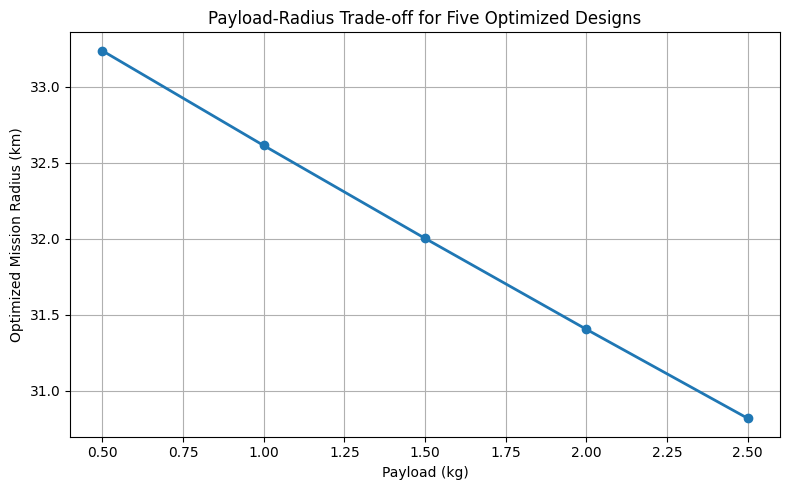


Results saved as five_payload_radius_designs.csv
Original payload restored to: 0.5 kg


In [9]:

import numpy as np
import pandas as pd
from scipy.optimize import minimize

# ============================================================
# FIVE OPTIMIZED VEHICLE DESIGNS: PAYLOAD-RADIUS TRADE-OFF
# ============================================================

# Payload values to investigate (kg)
payload_levels = [0.5, 1.0, 1.5, 2.0, 2.5]

# Save the original payload so it can be restored later
original_payload = payload

# Starting point for the first optimization
current_start = np.array(starting_design, dtype=float).copy()

# Store the five optimized designs
design_results = []

print("=" * 65)
print("FIVE OPTIMIZED VEHICLE DESIGNS")
print("PAYLOAD-RADIUS TRADE-OFF")
print("=" * 65)

try:
    for p in payload_levels:

        # Set the payload for this optimization
        payload = p

        # Optimize the vehicle design
        result = minimize(
            objective,
            current_start,
            method="SLSQP",
            bounds=bounds,
            constraints=[
                {
                    "type": "ineq",
                    "fun": structural_constraints
                }
            ],
            options={
                "maxiter": 1000,
                "ftol": 1e-10,
                "disp": False
            }
        )

        # Check whether the optimization succeeded
        if not result.success:
            raise RuntimeError(
                f"Optimization failed at payload {p} kg: "
                f"{result.message}"
            )

        # Extract optimized design variables
        D, E, d, t, V = result.x

        # Evaluate the optimized design
        performance = evaluate_design(result.x)

        # Calculate individual rotor maximum thrust
        Tmax = (
            2 * performance["loaded_mass"] * g / n
        )

        # Evaluate structural constraint margins
        margins = np.asarray(
            structural_constraints(result.x),
            dtype=float
        )

        # Check feasibility
        if np.min(margins) < -1e-6:
            raise RuntimeError(
                f"Design at payload {p} kg is infeasible. "
                f"Minimum constraint margin = {np.min(margins)}"
            )

        # Save results
        design = {
            "Payload (kg)": p,
            "Radius (km)": performance["radius"] / 1000,
            "D (m)": D,
            "E (Wh)": E,
            "d (mm)": d,
            "t (mm)": t,
            "V (m/s)": V,
            "Loaded mass (kg)": performance["loaded_mass"],
            "Empty mass (kg)": performance["empty_mass"],
            "Thrust per rotor (N)": Tmax,
            "Minimum constraint margin": np.min(margins)
        }

        design_results.append(design)

        # Use this solution as the next starting point
        current_start = result.x.copy()

        print(f"\nPayload: {p:.2f} kg")
        print(f"Mission radius: {performance['radius']/1000:.4f} km")
        print(f"Loaded mass: {performance['loaded_mass']:.4f} kg")
        print(f"Maximum thrust per rotor: {Tmax:.4f} N")
        print(f"Minimum constraint margin: {np.min(margins):.6e}")
        print("Optimization: SUCCESS")

finally:
    # Restore the original full-payload value
    payload = original_payload

# ============================================================
# DISPLAY THE FIVE-DESIGN RESULTS
# ============================================================

results_df = pd.DataFrame(design_results)

print("\n" + "=" * 65)
print("FINAL PAYLOAD-RADIUS TRADE-OFF TABLE")
print("=" * 65)

print(
    results_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

# ============================================================
# PLOT PAYLOAD AGAINST MISSION RADIUS
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Payload (kg)"],
    results_df["Radius (km)"],
    marker="o",
    linewidth=2
)

plt.xlabel("Payload (kg)")
plt.ylabel("Optimized Mission Radius (km)")
plt.title("Payload-Radius Trade-off for Five Optimized Designs")
plt.grid(True)
plt.tight_layout()
plt.show()

# ============================================================
# SAVE THE RESULTS
# ============================================================

results_df.to_csv(
    "five_payload_radius_designs.csv",
    index=False
)

print("\nResults saved as five_payload_radius_designs.csv")
print("Original payload restored to:", payload, "kg")


IDF CODE


In [3]:

# ==========================================================
# M1: IDF OPTIMIZATION
# Masses are additional optimization variables
# ==========================================================

def calculate_B(x, pay):

    D, E, d_mm, t_mm, V = x

    d = d_mm / 1000
    t = t_mm / 1000
    L = 0.78 * D - 0.08

    A_tube = (math.pi / 4) * (
        d**2 - (d - 2*t)**2
    )

    m_arm = rho_cf * A_tube * L

    B = (
        pay + m_fixed + m_plate + E/e_b
        + n*m_arm
        + n*(0.12 + 0.05*(D/0.6)**2.5)
    )

    return B


def evaluate_idf(z):

    D, E, d_mm, t_mm, V, m_loaded, m_empty = z

    d = d_mm / 1000
    t = t_mm / 1000
    L = 0.78*D - 0.08

    A_tube = (math.pi/4)*(
        d**2 - (d-2*t)**2
    )

    I = (math.pi/64)*(
        d**4 - (d-2*t)**4
    )

    m_arm = rho_cf*A_tube*L

    T_max = 2*m_loaded*g/n

    m_tip = (
        0.12 + 0.004*T_max
        + 0.05*(D/0.6)**2.5
    )

    def calculate_power(mass):

        W = mass*g
        A = math.pi*D**2/4

        v_h = math.sqrt(
            W/(2*rho*n*A)
        )

        v_i = math.sqrt(
            -V**2/2
            + math.sqrt(V**4/4 + v_h**4)
        )

        P_hover = W*v_h/(FM*eta) + P_av

        mu = V/V_tip

        P_cruise = (
            (
                W*v_i
                + W*v_h*(
                    math.sqrt(1+4.65*mu**2)-1
                )
                + 0.5*rho*CdA*V**3
            )/(FM*eta)
            + P_av
        )

        return P_hover, P_cruise

    PhL, PcL = calculate_power(m_loaded)
    PhE, PcE = calculate_power(m_empty)

    E_use = 3600*0.80*0.85*E

    radius = (
        V*(E_use - 60*(PhL+PhE))/(PcL+PcE)
    )

    stress = T_max*L*(d/2)/I

    deflection = T_max*L**3/(3*E_cf*I)

    allowable_deflection = 0.01*L

    frequency = (
        1/(2*math.pi)
        * math.sqrt(
            3*E_cf*I /
            (L**3*(m_tip+0.24*m_arm))
        )
    )

    required_frequency = 1.15*V_tip/(math.pi*D)

    slenderness = d/t

    return {
        "radius": radius,
        "thrust": T_max,
        "stress": stress,
        "deflection": deflection,
        "allowable_deflection": allowable_deflection,
        "frequency": frequency,
        "required_frequency": required_frequency,
        "slenderness": slenderness
    }


# Objective
def idf_objective(z):

    return -evaluate_idf(z)["radius"]/1000


# Mass consistency equality constraints
def idf_mass_constraints(z):

    x = z[:5]
    m_loaded = z[5]
    m_empty = z[6]

    B_loaded = calculate_B(x, payload)
    B_empty = calculate_B(x, 0.0)

    return np.array([
        (0.92152*m_loaded-B_loaded)/20,
        (0.92152*m_empty-B_empty)/20
    ])


# Structural inequality constraints
def idf_structural_constraints(z):

    r = evaluate_idf(z)

    return np.array([
        (200e6-r["stress"])/200e6,

        (r["allowable_deflection"]-r["deflection"])
        /r["allowable_deflection"],

        (r["frequency"]-r["required_frequency"])
        /r["required_frequency"],

        (40-r["slenderness"])/40
    ])


# Initial values from the MDF solution
x_mdf = result.x.copy()

mdf_values = evaluate_design(x_mdf)

z0 = np.array([
    *x_mdf,
    mdf_values["loaded_mass"],
    mdf_values["empty_mass"]
])


# Bounds:
# First five are the given design-variable bounds.
# The 1–100 kg mass bounds are broad numerical bounds
# for the additional IDF mass variables.
idf_bounds = bounds + [
    (1, 100),
    (1, 100)
]


# Run IDF
idf_result = minimize(
    idf_objective,
    z0,
    method="SLSQP",
    bounds=idf_bounds,
    constraints=[
        {
            "type": "eq",
            "fun": idf_mass_constraints
        },
        {
            "type": "ineq",
            "fun": idf_structural_constraints
        }
    ],
    options={
        "maxiter": 2000,
        "ftol": 1e-10,
        "disp": True
    }
)


# Display results
print("\n========== IDF OPTIMIZATION RESULTS ==========")

print("Optimizer success:", idf_result.success)
print("Message:", idf_result.message)

if idf_result.success:

    z_opt = idf_result.x
    r_idf = evaluate_idf(z_opt)

    print("\nDESIGN VARIABLES")
    print("Rotor diameter:", z_opt[0], "m")
    print("Battery capacity:", z_opt[1], "Wh")
    print("Arm diameter:", z_opt[2], "mm")
    print("Wall thickness:", z_opt[3], "mm")
    print("Cruise speed:", z_opt[4], "m/s")

    print("\nOPTIMIZED MASSES")
    print("Loaded mass:", z_opt[5], "kg")
    print("Empty mass:", z_opt[6], "kg")

    print("\nPERFORMANCE")
    print("Mission radius:", r_idf["radius"]/1000, "km")

    print("\nMASS CONSISTENCY RESIDUALS")
    print(idf_mass_constraints(z_opt))

    print("\nSTRUCTURAL CONSTRAINT MARGINS")
    print(idf_structural_constraints(z_opt))

    # Compare IDF with MDF
    mdf_radius = mdf_values["radius"]/1000
    idf_radius = r_idf["radius"]/1000

    difference = (
        abs(idf_radius-mdf_radius)/mdf_radius*100
    )

    print("\n========== MDF vs IDF ==========")
    print("MDF radius:", mdf_radius, "km")
    print("IDF radius:", idf_radius, "km")
    print("Percentage difference:", difference, "%")

    if difference <= 1:
        print("MDF and IDF AGREE WITHIN 1%")
    else:
        print("MDF and IDF DO NOT AGREE WITHIN 1%")

else:
    print("IDF did not converge. Do not report it as verified.")


Optimization terminated successfully    (Exit mode 0)
            Current function value: -30.817962189966543
            Iterations: 1
            Function evaluations: 8
            Gradient evaluations: 1

========== IDF OPTIMIZATION RESULTS ==========
Optimizer success: True
Message: Optimization terminated successfully

DESIGN VARIABLES
Rotor diameter: 0.799999999998457 m
Battery capacity: 2000.0 Wh
Arm diameter: 40.0 mm
Wall thickness: 2.496411053422949 mm
Cruise speed: 18.94284633691821 m/s

OPTIMIZED MASSES
Loaded mass: 20.147076561733023 kg
Empty mass: 17.434167455039734 kg

PERFORMANCE
Mission radius: 30.817962189966543 km

MASS CONSISTENCY RESIDUALS
[0. 0.]

STRUCTURAL CONSTRAINT MARGINS
[8.96501171e-01 7.31888749e-01 1.53351955e-12 5.99424943e-01]

========== MDF vs IDF ==========
MDF radius: 30.817962189966543 km
IDF radius: 30.817962189966543 km
Percentage difference: 0.0 %
MDF and IDF AGREE WITHIN 1%


Replacing IDF

In [4]:

# ==========================================================
# M1: IDF OPTIMIZATION
# Masses are additional optimization variables
# ==========================================================

def calculate_B(x, pay):

    D, E, d_mm, t_mm, V = x

    d = d_mm / 1000
    t = t_mm / 1000
    L = 0.78 * D - 0.08

    A_tube = (math.pi / 4) * (
        d**2 - (d - 2*t)**2
    )

    m_arm = rho_cf * A_tube * L

    B = (
        pay + m_fixed + m_plate + E/e_b
        + n*m_arm
        + n*(0.12 + 0.05*(D/0.6)**2.5)
    )

    return B


def evaluate_idf(z):

    D, E, d_mm, t_mm, V, m_loaded, m_empty = z

    d = d_mm / 1000
    t = t_mm / 1000
    L = 0.78*D - 0.08

    A_tube = (math.pi/4)*(
        d**2 - (d-2*t)**2
    )

    I = (math.pi/64)*(
        d**4 - (d-2*t)**4
    )

    m_arm = rho_cf*A_tube*L

    T_max = 2*m_loaded*g/n

    m_tip = (
        0.12 + 0.004*T_max
        + 0.05*(D/0.6)**2.5
    )

    def calculate_power(mass):

        W = mass*g
        A = math.pi*D**2/4

        v_h = math.sqrt(
            W/(2*rho*n*A)
        )

        v_i = math.sqrt(
            -V**2/2
            + math.sqrt(V**4/4 + v_h**4)
        )

        P_hover = W*v_h/(FM*eta) + P_av

        mu = V/V_tip

        P_cruise = (
            (
                W*v_i
                + W*v_h*(
                    math.sqrt(1+4.65*mu**2)-1
                )
                + 0.5*rho*CdA*V**3
            )/(FM*eta)
            + P_av
        )

        return P_hover, P_cruise

    PhL, PcL = calculate_power(m_loaded)
    PhE, PcE = calculate_power(m_empty)

    E_use = 3600*0.80*0.85*E

    radius = (
        V*(E_use - 60*(PhL+PhE))/(PcL+PcE)
    )

    stress = T_max*L*(d/2)/I

    deflection = T_max*L**3/(3*E_cf*I)

    allowable_deflection = 0.01*L

    frequency = (
        1/(2*math.pi)
        * math.sqrt(
            3*E_cf*I /
            (L**3*(m_tip+0.24*m_arm))
        )
    )

    required_frequency = 1.15*V_tip/(math.pi*D)

    slenderness = d/t

    return {
        "radius": radius,
        "thrust": T_max,
        "stress": stress,
        "deflection": deflection,
        "allowable_deflection": allowable_deflection,
        "frequency": frequency,
        "required_frequency": required_frequency,
        "slenderness": slenderness
    }


# Objective
def idf_objective(z):

    return -evaluate_idf(z)["radius"]/1000


# Mass consistency equality constraints
def idf_mass_constraints(z):

    x = z[:5]
    m_loaded = z[5]
    m_empty = z[6]

    B_loaded = calculate_B(x, payload)
    B_empty = calculate_B(x, 0.0)

    return np.array([
        (0.92152*m_loaded-B_loaded)/20,
        (0.92152*m_empty-B_empty)/20
    ])


# Structural inequality constraints
def idf_structural_constraints(z):

    r = evaluate_idf(z)

    return np.array([
        (200e6-r["stress"])/200e6,

        (r["allowable_deflection"]-r["deflection"])
        /r["allowable_deflection"],

        (r["frequency"]-r["required_frequency"])
        /r["required_frequency"],

        (40-r["slenderness"])/40
    ])


# Independent IDF starting point
x_start = np.array([0.575, 1100, 32, 2.5, 15.0])

trial = evaluate_design(x_start)

z0 = np.array([
    *x_start,
    trial["loaded_mass"],
    trial["empty_mass"]
])


# Bounds:
# First five are the given design-variable bounds.
# The 1–100 kg mass bounds are broad numerical bounds
# for the additional IDF mass variables.
idf_bounds = bounds + [
    (1, 100),
    (1, 100)
]


# Run IDF
idf_result = minimize(
    idf_objective,
    z0,
    method="SLSQP",
    bounds=idf_bounds,
    constraints=[
        {
            "type": "eq",
            "fun": idf_mass_constraints
        },
        {
            "type": "ineq",
            "fun": idf_structural_constraints
        }
    ],
    options={
        "maxiter": 2000,
        "ftol": 1e-10,
        "disp": True
    }
)


# Display results
print("\n========== IDF OPTIMIZATION RESULTS ==========")

print("Optimizer success:", idf_result.success)
print("Message:", idf_result.message)

if idf_result.success:

    z_opt = idf_result.x
    r_idf = evaluate_idf(z_opt)

    print("\nDESIGN VARIABLES")
    print("Rotor diameter:", z_opt[0], "m")
    print("Battery capacity:", z_opt[1], "Wh")
    print("Arm diameter:", z_opt[2], "mm")
    print("Wall thickness:", z_opt[3], "mm")
    print("Cruise speed:", z_opt[4], "m/s")

    print("\nOPTIMIZED MASSES")
    print("Loaded mass:", z_opt[5], "kg")
    print("Empty mass:", z_opt[6], "kg")

    print("\nPERFORMANCE")
    print("Mission radius:", r_idf["radius"]/1000, "km")

    print("\nMASS CONSISTENCY RESIDUALS")
    print(idf_mass_constraints(z_opt))

    print("\nSTRUCTURAL CONSTRAINT MARGINS")
    print(idf_structural_constraints(z_opt))

    # Compare IDF with MDF
    mdf_radius = mdf_values["radius"]/1000
    idf_radius = r_idf["radius"]/1000

    difference = (
        abs(idf_radius-mdf_radius)/mdf_radius*100
    )

    print("\n========== MDF vs IDF ==========")
    print("MDF radius:", mdf_radius, "km")
    print("IDF radius:", idf_radius, "km")
    print("Percentage difference:", difference, "%")

    if difference <= 1:
        print("MDF and IDF AGREE WITHIN 1%")
    else:
        print("MDF and IDF DO NOT AGREE WITHIN 1%")

else:
    print("IDF did not converge. Do not report it as verified.")


Optimization terminated successfully    (Exit mode 0)
            Current function value: -30.817962190052086
            Iterations: 20
            Function evaluations: 160
            Gradient evaluations: 20

========== IDF OPTIMIZATION RESULTS ==========
Optimizer success: True
Message: Optimization terminated successfully

DESIGN VARIABLES
Rotor diameter: 0.8 m
Battery capacity: 2000.0 Wh
Arm diameter: 40.0 mm
Wall thickness: 2.496411053425656 mm
Cruise speed: 18.942859932288737 m/s

OPTIMIZED MASSES
Loaded mass: 20.147076561738775 kg
Empty mass: 17.434167455045486 kg

PERFORMANCE
Mission radius: 30.817962190052086 km

MASS CONSISTENCY RESIDUALS
[6.03961325e-15 6.21724894e-15]

STRUCTURAL CONSTRAINT MARGINS
[ 8.96501171e-01  7.31888749e-01 -7.62312950e-15  5.99424943e-01]

========== MDF vs IDF ==========
MDF radius: 30.817962189966543 km
IDF radius: 30.817962190052086 km
Percentage difference: 2.7757266827333766e-10 %
MDF and IDF AGREE WITHIN 1%


Gradient verification

In [5]:

# ==========================================================
# M1: FINITE-DIFFERENCE GRADIENT VERIFICATION
# ==========================================================

x_opt = result.x.copy()

# Relative perturbation sizes
step_sizes = [1e-4, 5e-5]

# Scale each variable so that perturbations are appropriate
# for metres, Wh, mm and m/s.
scales = np.maximum(np.abs(x_opt), 1.0)


def central_difference_gradient(function, x, step):

    x = np.asarray(x, dtype=float)
    f0 = np.atleast_1d(function(x))
    gradient = np.zeros((len(f0), len(x)))

    for j in range(len(x)):

        h = step * scales[j]

        x_plus = x.copy()
        x_minus = x.copy()

        x_plus[j] += h
        x_minus[j] -= h

        f_plus = np.atleast_1d(function(x_plus))
        f_minus = np.atleast_1d(function(x_minus))

        gradient[:, j] = (
            f_plus - f_minus
        ) / (2*h)

    return gradient


print("\n========== GRADIENT VERIFICATION ==========")

gradients = {}

for step in step_sizes:

    grad_obj = central_difference_gradient(
        objective, x_opt, step
    )

    grad_constraints = central_difference_gradient(
        structural_constraints, x_opt, step
    )

    gradients[step] = (grad_obj, grad_constraints)

    print("\nStep size:", step)

    print("Objective gradient:")
    print(grad_obj)

    print("Structural constraint gradients:")
    print(grad_constraints)


# Compare the two step sizes
g_obj_1, g_con_1 = gradients[step_sizes[0]]
g_obj_2, g_con_2 = gradients[step_sizes[1]]

obj_difference = (
    np.linalg.norm(g_obj_1-g_obj_2)
    / max(np.linalg.norm(g_obj_2), 1e-12)
) * 100

constraint_difference = (
    np.linalg.norm(g_con_1-g_con_2)
    / max(np.linalg.norm(g_con_2), 1e-12)
) * 100

print("\n========== STEP-SIZE COMPARISON ==========")

print(
    "Objective gradient difference:",
    obj_difference, "%"
)

print(
    "Constraint gradient difference:",
    constraint_difference, "%"
)

print("\n========== END GRADIENT VERIFICATION ==========")



========== GRADIENT VERIFICATION ==========

Step size: 0.0001
Objective gradient:
[[-3.54112474e+01 -2.76770690e-03  5.34337764e-02  7.49301969e-01
  -4.53928168e-06]]
Structural constraint gradients:
[[-1.63480814e-01 -3.71644212e-05  5.51983526e-03  3.15022234e-02
   0.00000000e+00]
 [-8.07917379e-01 -9.62735483e-05  2.10017835e-02  8.16057596e-02
   0.00000000e+00]
 [-1.24297221e+00 -1.04760351e-04  3.82914918e-02  1.39920733e-01
   0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00 -1.00143764e-02  1.60460378e-01
   0.00000000e+00]]

Step size: 5e-05
Objective gradient:
[[-3.54112474e+01 -2.76770687e-03  5.34337764e-02  7.49301969e-01
  -4.51801830e-06]]
Structural constraint gradients:
[[-1.63480814e-01 -3.71644212e-05  5.51983516e-03  3.15022231e-02
   0.00000000e+00]
 [-8.07917378e-01 -9.62735483e-05  2.10017830e-02  8.16057590e-02
   0.00000000e+00]
 [-1.24297220e+00 -1.04760350e-04  3.82914918e-02  1.39920733e-01
   0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00 -1.0014376

payload

In [6]:

# ==========================================================
# M1: PAYLOAD SENSITIVITY
# ==========================================================

payload_levels = [2.3, 2.4, 2.5]

payload_results = []

for p in payload_levels:

    # Set the payload used by the MDF analysis
    payload = p

    # Re-optimize from the verified MDF optimum
    sensitivity_result = minimize(
        objective,
        result.x.copy(),
        method="SLSQP",
        bounds=bounds,
        constraints=[
            {
                "type": "ineq",
                "fun": structural_constraints
            }
        ],
        options={
            "maxiter": 2000,
            "ftol": 1e-9,
            "disp": False
        }
    )

    print("\nPayload:", p, "kg")
    print("Solver success:", sensitivity_result.success)
    print("Message:", sensitivity_result.message)

    if sensitivity_result.success:

        performance = evaluate_design(sensitivity_result.x)

        radius_km = performance["radius"] / 1000

        print("Optimized radius:", radius_km, "km")
        print("Design variables:", sensitivity_result.x)

        payload_results.append((p, radius_km))

    else:
        print("Do not use this result for sensitivity calculations.")


# Calculate radius lost per additional 100 g
print("\n========== PAYLOAD SENSITIVITY RESULTS ==========")

if len(payload_results) == 3:

    for i in range(2):

        p1, r1 = payload_results[i]
        p2, r2 = payload_results[i+1]

        loss = r1-r2

        print(
            f"Payload increase: {p1:.1f} to {p2:.1f} kg"
        )
        print(
            f"Mission radius lost: {loss:.6f} km per 100 g"
        )

    average_loss = (
        (payload_results[0][1]-payload_results[2][1])/2
    )

    print(
        "\nAverage radius lost per 100 g:",
        average_loss,
        "km"
    )

else:
    print("Sensitivity calculation incomplete.")

# Restore the original full payload
payload = 2.5

print("\nOriginal payload restored:", payload, "kg")
print("========== END PAYLOAD SENSITIVITY ==========")



Payload: 2.3 kg
Solver success: True
Message: Optimization terminated successfully
Optimized radius: 31.050724181131194 km
Design variables: [8.00000000e-01 2.00000000e+03 4.00000000e+01 2.47399735e+00
 1.88840997e+01]

Payload: 2.4 kg
Solver success: True
Message: Optimization terminated successfully
Optimized radius: 30.93409004993249 km
Design variables: [8.00000000e-01 2.00000000e+03 4.00000000e+01 2.48519231e+00
 1.89134673e+01]

Payload: 2.5 kg
Solver success: True
Message: Optimization terminated successfully
Optimized radius: 30.817962189966543 km
Design variables: [8.00000000e-01 2.00000000e+03 4.00000000e+01 2.49641105e+00
 1.89428463e+01]

========== PAYLOAD SENSITIVITY RESULTS ==========
Payload increase: 2.3 to 2.4 kg
Mission radius lost: 0.116634 km per 100 g
Payload increase: 2.4 to 2.5 kg
Mission radius lost: 0.116128 km per 100 g

Average radius lost per 100 g: 0.1163809955823254 km

Original payload restored: 2.5 kg
========== END PAYLOAD SENSITIVITY ==========


In [7]:
refined_payloads = [2.49, 2.50]
refined_radii = []

for p in refined_payloads:
    payload = p

    opt = minimize(
        objective,
        result.x.copy(),
        method="SLSQP",
        bounds=bounds,
        constraints=[
            {"type": "ineq", "fun": structural_constraints}
        ],
        options={"maxiter": 2000, "ftol": 1e-10}
    )

    if opt.success:
        radius = evaluate_design(opt.x)["radius"] / 1000
        refined_radii.append(radius)
        print("Payload:", p, "kg")
        print("Mission radius:", radius, "km")
    else:
        print("Optimization failed at", p, "kg")

payload = 2.5

if len(refined_radii) == 2:
    loss_per_100g = (refined_radii[0] - refined_radii[1]) * 10
    print("Radius lost per additional 100 g:", loss_per_100g, "km")
    print("Radius lost in metres:", loss_per_100g * 1000, "m")

Payload: 2.49 kg
Mission radius: 30.829552199466168 km
Payload: 2.5 kg
Mission radius: 30.817962189966543 km
Radius lost per additional 100 g: 0.11590009499624188 km
Radius lost in metres: 115.90009499624188 m
